In [2]:
import sys
sys.path.append('../../')

import matplotlib.pyplot as plt

# Import methods
import QGP.Defocusing.Methods as Def
import QGP.Focusing.Methods as Foc
from QGP.Soliton_Gen import *
from Utilities import *

import config

In [6]:
# ---------------------------------------------------------
# Discrete operators from Lemma 2.4
# ---------------------------------------------------------

def neumann_laplacian(J, h):
    """
    Matrix A approximating D_xx with homogeneous Neumann BCs.

    Input:
        J : last grid index, so vectors have length J+1
        h : space step

    Output:
        A : (J+1) x (J+1) matrix
    """
    n = J + 1
    A = np.zeros((n, n), dtype=float)

    # Left boundary: (2u_1 - 2u_0)/h^2
    A[0, 0] = -2
    A[0, 1] =  2

    # Interior nodes
    for j in range(1, J):
        A[j, j-1] =  1
        A[j, j]   = -2
        A[j, j+1] =  1

    # Right boundary: (2u_{J-1} - 2u_J)/h^2
    A[J, J-1] =  2
    A[J, J]   = -2

    return A / h**2


def trap_inner(u, v, h):
    """
    Trapezoidal discrete inner product.

    For real vectors:
        <u,v>_h = h * (1/2 u_0 v_0 + sum u_j v_j + 1/2 u_J v_J)

    For complex vectors:
        <u,v>_h = h * Re( sum weights * u_j * conj(v_j) )
    """
    weights = np.ones_like(u, dtype=float)
    weights[0] = 0.5
    weights[-1] = 0.5

    return h * np.real(np.sum(weights * u * np.conj(v)))


def forward_diff(u, h):
    """
    Forward finite difference D_x^{h,+} u.
    Returns a vector of length J if u has length J+1.
    """
    return (u[1:] - u[:-1]) / h


def lemma_left_side(u, v, A, h):
    return trap_inner(A @ u, v, h)


def lemma_right_side(u, v, h):
    Du = forward_diff(u, h)
    Dv = forward_diff(v, h)
    return -h * np.real(np.sum(Du * np.conj(Dv)))


# ---------------------------------------------------------
# Single random test
# ---------------------------------------------------------

J = 10-000
L = 10.0
h = 2 * L / J

A = neumann_laplacian(J, h)

rng = np.random.default_rng(123)

u = rng.normal(size=J+1)
v = rng.normal(size=J+1)

lhs = lemma_left_side(u, v, A, h)
rhs = lemma_right_side(u, v, h)

print("Real random vectors")
print("Left side  <Au,v>_h       =", lhs)
print("Right side -h sum Dx u Dx v =", rhs)
print("Absolute error             =", abs(lhs - rhs))
print("Relative error             =", abs(lhs - rhs) / max(1, abs(lhs), abs(rhs)))

Real random vectors
Left side  <Au,v>_h       = 0.26494304526875323
Right side -h sum Dx u Dx v = 0.26494304526875356
Absolute error             = 3.3306690738754696e-16
Relative error             = 3.3306690738754696e-16



Complex vectors:
Max absolute error: 7.105427357601002e-15
Max relative error: 2.6645352591003757e-15


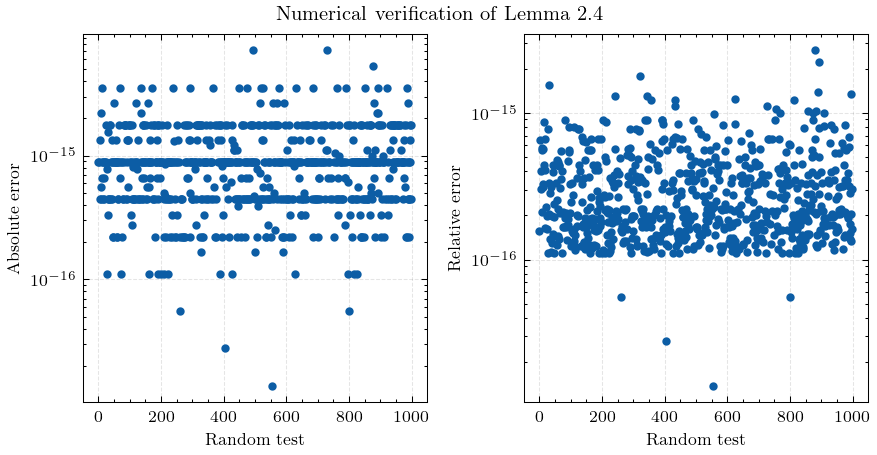

In [8]:
# ---------------------------------------------------------
# Many random tests + plot
# ---------------------------------------------------------

def run_random_tests(J=50, L=10.0, ntests=1_000, complex_vectors=False, seed=67):
    h = 2 * L / J
    A = neumann_laplacian(J, h)
    rng = np.random.default_rng(seed)

    abs_errors = []
    rel_errors = []

    for _ in range(ntests):
        if complex_vectors:
            u = rng.normal(size=J+1) + 1j * rng.normal(size=J+1)
            v = rng.normal(size=J+1) + 1j * rng.normal(size=J+1)
        else:
            u = rng.normal(size=J+1)
            v = rng.normal(size=J+1)

        lhs = lemma_left_side(u, v, A, h)
        rhs = lemma_right_side(u, v, h)

        abs_err = abs(lhs - rhs)
        rel_err = abs_err / max(1, abs(lhs), abs(rhs))

        abs_errors.append(abs_err)
        rel_errors.append(rel_err)

    return np.array(abs_errors), np.array(rel_errors)

J = 10-000
L = 10.0

abs_err_cplx, rel_err_cplx = run_random_tests(J=J, L=L, complex_vectors=True)

print("\nComplex vectors:")
print("Max absolute error:", abs_err_cplx.max())
print("Max relative error:", rel_err_cplx.max())


fig, axs = plt.subplots(1, 2, figsize=(6, 3))
axs[0].semilogy(abs_err_cplx, ".")
axs[0].set_xlabel("Random test")
axs[0].set_ylabel("Absolute error")

axs[1].semilogy(rel_err_cplx, ".")
axs[1].set_xlabel("Random test")
axs[1].set_ylabel("Relative error")
plt.tight_layout()
plt.suptitle("Numerical verification of Lemma 2.4", y=1.02)
plt.savefig("Img/Lemma_2_4/errors.pdf", dpi=300, bbox_inches='tight')
plt.show()

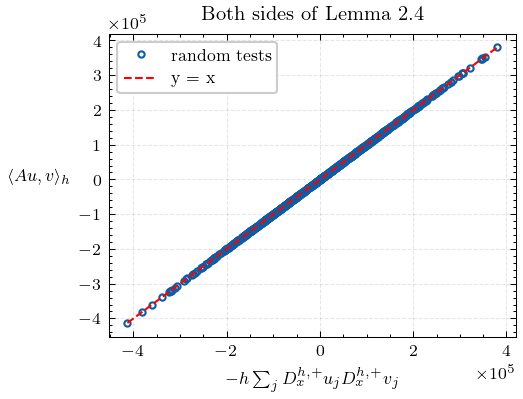

In [9]:
# ---------------------------------------------------------
# Scatter plot: LHS vs RHS
# ---------------------------------------------------------

J = 10_000
L = 10.0
h = 2 * L / J
A = neumann_laplacian(J, h)

rng = np.random.default_rng(67)
ntests = 1_000

lhs_values = []
rhs_values = []

for _ in range(ntests):
    u = rng.normal(size=J+1)
    v = rng.normal(size=J+1)

    lhs_values.append(lemma_left_side(u, v, A, h))
    rhs_values.append(lemma_right_side(u, v, h))

rhs_values = np.array(lhs_values)
lhs_values = np.array(rhs_values)

plt.figure()
plt.plot(lhs_values, rhs_values, ".", label="random tests", markerfacecolor='none')

m = min(lhs_values.min(), rhs_values.min())
M = max(lhs_values.max(), rhs_values.max())
plt.plot([m, M], [m, M], "r--", label="y = x")

plt.ticklabel_format(style='sci', axis='y', scilimits=(0,0))
plt.ticklabel_format(style='sci', axis='x', scilimits=(0,0))
plt.ylabel(r"$\langle Au, v\rangle_h$", rotation=0, ha="right")
plt.xlabel(r"$-h \sum_j D_x^{h,+}u_j D_x^{h,+}v_j$")
plt.xticks()
plt.title("Both sides of Lemma 2.4")
plt.legend()

plt.savefig("Img/Lemma_2_4/identity.pdf", dpi=300, bbox_inches='tight')
plt.show()